# Progressive's monthly loss ratio

Pulls Progressive's monthly results from SEC filings to compare an actual insurer's loss ratio with the cost and premium trends

In [1]:
#The plan:
#Find the filings: get the list of Progressive’s monthly reports from the SEC
#Open one report and find the results table inside it
#Pull the loss/LAE ratio out of that table
#Repeat for every month and save it to SQLite
#Analyze and chart it (notebook 4)
#Add it to update.py, the workflow, and Excel

In [2]:
import os
import requests
import pandas as pd
from dotenv import load_dotenv

load_dotenv()
headers = {"User-Agent": os.getenv("SEC_USER_AGENT")}

#every filing Progressive has made recently (CIK 80661: 80661 is Progressive's id)
url = "https://data.sec.gov/submissions/CIK0000080661.json"
response = requests.get(url, headers=headers, timeout=30)
print(response.status_code)

recent = pd.DataFrame(response.json()["filings"]["recent"])
recent[["form", "filingDate", "items"]].head(10)

200


,form,filingDate,items
0,8-K,2026-11-18,"7.01,9.01"
1,4,2026-11-06,
2,10-Q,2026-11-02,
3,3,2026-10-26,
4,4,2026-10-26,
5,144,2026-10-22,
6,8-K,2026-10-14,"2.02,9.01"
7,4,2026-10-13,
8,4,2026-10-13,
9,4,2026-10-13,


Monthly results are 8-Ks filed under Item 2.02, “Results of Operations." We see an 8-K was filed today, 11-18, so we need to keep 8-Ks whos items contain 2.02 or 7.01

In [3]:
#keep only 8-Ks filed under 2.02 (quarter-end results) or 7.01 (other months)
monthly_8k = recent[(recent["form"] == "8-K") & (recent["items"].str.contains("2.02|7.01"))]
monthly_8k[["filingDate", "accessionNumber", "items"]]

,filingDate,accessionNumber,items
0,2026-11-18,0000080661-26-000384,"7.01,9.01"
6,2026-10-14,0000080661-26-000367,"2.02,9.01"
29,2026-09-18,0000080661-26-000322,"7.01,9.01"
34,2026-08-19,0000080661-26-000315,"7.01,9.01"
37,2026-08-10,0000080661-26-000310,"7.01,9.01"
68,2026-07-15,0000080661-26-000262,"2.02,9.01"
96,2026-06-17,0000080661-26-000210,"5.02,7.01,9.01"
101,2026-05-20,0000080661-26-000204,"7.01,9.01"
103,2026-05-12,0000080661-26-000200,"5.02,5.07,7.01,9.01"
118,2026-04-15,0000080661-26-000173,"2.02,9.01"


The breakdown: 7.01, 9.01 is the usual monthly results. 2.02, 9.01 is the quarter-end months filed alongside quarterly reports (Jan, Apr, July, Oct). 5.02, 5.07 are the executive changes or shareholder votes. 8.01 is other events; we don't need this. We will be focusing on 2.02, 7.01, and 9.01.

In [4]:
#list the files inside the newest filing
accession = monthly_8k["accessionNumber"].iloc[0].replace("-", "")
index_url = f"https://www.sec.gov/Archives/edgar/data/80661/{accession}/index.json"

index_response = requests.get(index_url, headers=headers, timeout=30)
files = pd.DataFrame(index_response.json()["directory"]["item"])
files[["name", "size"]]

,name,size
0,0000080661-26-000384-index-headers.html,
1,0000080661-26-000384-index.html,
2,0000080661-26-000384.txt,
3,0000080661-26-000384-xbrl.zip,24687
4,FilingSummary.xml,1633
5,image0a04a01a67.jpg,100583
6,MetaLinks.json,17111
7,pgr-20261118.htm,34604
8,pgr-20261118.xsd,1804
9,pgr-20261118_htm.xml,2712


We want loss/LAE ratio since it is the one number that will connect claim costs and premiums. Loss/LAE ratio = (claims paid + claim-handling costs) / premiums earned. Losses are what Progressive pays out on claims, LAE (Loss adjusted expense) is what it costs to handle those claims (adjusters, lawyers, investigators), and premiums earned are what the customers paid for the coverage; this is exactly what we're trying to measure for this project.

In [5]:
from io import StringIO

#open the press release (Exhibit 99)
ex99_name = files[files["name"].str.contains("ex99")]["name"].iloc[0]
ex99_url = f"https://www.sec.gov/Archives/edgar/data/80661/{accession}/{ex99_name}"
html = requests.get(ex99_url, headers=headers, timeout=30).text

#keep only tables that mention LAE (loss adjustment expense)
lae_tables = pd.read_html(StringIO(html), match="LAE")
print(len(lae_tables))
lae_tables[0]

3


,0,1,2,3,4,5,6,7,8,9,...,26,27,28,29,30,31,32,33,34,35
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Current Month,Current Month,Current Month,Current Month,Current Month,Current Month,Current Month,Current Month,Current Month,Current Month,...,Current Month,Current Month,Current Month,Current Month,Current Month,Current Month,Current Month,Current Month,Current Month,Current Month
2,NaN,NaN,NaN,Personal Lines Business,Personal Lines Business,Personal Lines Business,Personal Lines Business,Personal Lines Business,Personal Lines Business,Personal Lines Business,...,NaN,Commercial,Commercial,Commercial,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,Vehicles,Vehicles,Vehicles,Vehicles,Vehicles,Vehicles,Vehicles,...,NaN,Lines,Lines,Lines,NaN,NaN,NaN,Companywide,Companywide,Companywide
4,NaN,NaN,NaN,Agency,Agency,Agency,NaN,NaN,NaN,Direct,...,NaN,Business,Business,Business,NaN,NaN,NaN,Total,Total,Total
5,Net Premiums Written,Net Premiums Written,Net Premiums Written,$,2547,NaN,NaN,NaN,NaN,$,...,NaN,$,849,NaN,NaN,NaN,NaN,$,7079,NaN
6,% Growth in NPW,% Growth in NPW,% Growth in NPW,0%,0%,0%,NaN,NaN,NaN,1%,...,NaN,4%,4%,4%,NaN,NaN,NaN,1%,1%,1%
7,Net Premiums Earned,Net Premiums Earned,Net Premiums Earned,$,2521,NaN,NaN,NaN,NaN,$,...,NaN,$,914,NaN,NaN,NaN,NaN,$,7166,NaN
8,% Growth in NPE,% Growth in NPE,% Growth in NPE,(1)%,(1)%,(1)%,NaN,NaN,NaN,2%,...,NaN,2%,2%,2%,NaN,NaN,NaN,1%,1%,1%
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
#cleaning: combine the stacked header rows into one label per column, then pair them with the Loss/LAE values
table = lae_tables[0]
header = table.iloc[2:5].fillna("").astype(str).agg(" ".join).str.strip()
lae_row = table[table[0] == "Loss/LAE ratio"].iloc[0]

pd.DataFrame({"segment": header, "loss_lae": lae_row}).dropna().drop_duplicates()

,segment,loss_lae
0,,Loss/LAE ratio
3,Personal Lines Business Vehicles Agency,71.3
9,Personal Lines Business Vehicles Direct,74.1
15,Personal Lines Business Property,33.6
21,Personal Lines Business Total,71.2
27,Commercial Lines Business,62.8
33,Companywide Total,70.1


In [7]:
#now we need to pull Loss/LAE ratio, Net catastrophe loss ratio, and Net Premiums Earned from the press release
#returns one number per segment for the row whose label starts with the given text
def segment_values(table, label):
    header = table.iloc[2:5].fillna("").astype(str).agg(" ".join).str.strip()
    row = table[table[0].astype(str).str.startswith(label)].iloc[0]
    values = pd.DataFrame({"segment": header, "value": pd.to_numeric(row, errors="coerce")})
    return values.dropna().drop_duplicates().set_index("segment")["value"]

lae = segment_values(table, "Loss/LAE ratio")
cat = segment_values(table, "Net catastrophe loss ratio")
npe = segment_values(table, "Net Premiums Earned")
npe

segment
Personal Lines Business Vehicles Agency    2521.0
Personal Lines Business Vehicles Direct    3450.0
Personal Lines Business  Property           280.0
Personal Lines Business  Total             6251.0
Commercial Lines Business                   914.0
Companywide Total                          7166.0
Name: value, dtype: float64

In [8]:
#personal auto = agency + direct, weighted by premiums earned
auto = ["Personal Lines Business Vehicles Agency", "Personal Lines Business Vehicles Direct"]
weights = npe[auto]

auto_lae = (lae[auto] * weights).sum() / weights.sum()
auto_cat = (cat[auto] * weights).sum() / weights.sum()
auto_ex_cat = auto_lae - auto_cat

print(f"Personal auto loss/LAE ratio: {auto_lae:.1f}")
print(f"Catastrophe ratio: {auto_cat:.1f}")
print(f"Excluding catastrophes: {auto_ex_cat:.1f}")

Personal auto loss/LAE ratio: 72.9
Catastrophe ratio: 1.4
Excluding catastrophes: 71.5


This covers all the data I need to pull, clean, and organize... from October 2026. For October 2026, the loss/LAE ratio was 72.9, or 71.5 without the cat ratio. Next, I need to wrap these steps up into a function and run it for every month back to 2022.

In [9]:
#pulls personal auto results from one filing, or returns None if the filing isn't a monthly results release
def month_results(accession, filing_date):
    folder = f"https://www.sec.gov/Archives/edgar/data/80661/{accession.replace('-', '')}"
    files = pd.DataFrame(requests.get(f"{folder}/index.json", headers=headers, timeout=30).json()["directory"]["item"])
    ex99 = files[files["name"].str.contains("ex99", case=False)]
    if ex99.empty:
        return None
    html = requests.get(f"{folder}/{ex99['name'].iloc[0]}", headers=headers, timeout=30).text
    try:
        table = pd.read_html(StringIO(html), match="LAE")[0]
    except ValueError:
        return None 
        #given no loss/LAE table, so not a monthly results release

    lae = segment_values(table, "Loss/LAE ratio")
    cat = segment_values(table, "Net catastrophe loss ratio")
    npe = segment_values(table, "Net Premiums Earned")

#old layout (before about 2025): Property was its own segment, so Personal Lines Total = personal auto
#new layout: Property is inside Personal Lines, so combine Agency and Direct, weighted by premium
    pl_total = next((s for s in npe.index if "Personal Lines" in s and "Total" in s), None)
    property_in_pl = any("Personal Lines" in s and "Property" in s for s in npe.index)

    if pl_total and not property_in_pl:
        auto_lae = lae[pl_total]
        auto_cat = cat.get(pl_total, float("nan"))
        auto_premium = npe[pl_total]
    else:
        agency = next(s for s in npe.index if "Agency" in s)
        direct = next(s for s in npe.index if "Direct" in s)
        weights = npe[[agency, direct]]
        auto_lae = (lae[[agency, direct]] * weights).sum() / weights.sum()
        if agency in cat.index and direct in cat.index:
            auto_cat = (cat[[agency, direct]] * weights).sum() / weights.sum()
        else:
            auto_cat = float("nan")  #no auto-only catastrophe ratio this month
        auto_premium = weights.sum()

    return {"month": (pd.Timestamp(filing_date) - pd.DateOffset(months=1)).strftime("%Y-%m-01"),
            "auto_lae": auto_lae,
            "auto_cat": auto_cat,
            "auto_premium": auto_premium}

In [10]:
month_results(monthly_8k["accessionNumber"].iloc[0], monthly_8k["filingDate"].iloc[0])

{'month': '2026-10-01',
 'auto_lae': np.float64(72.91781946072683),
 'auto_cat': np.float64(1.4),
 'auto_premium': np.float64(5971.0)}

In [11]:
import time

#run the function on every filing, keeping results and noting anything skipped
rows = []
skipped = []
for accession, filing_date in zip(monthly_8k["accessionNumber"], monthly_8k["filingDate"]):
    try:
        result = month_results(accession, filing_date)
    except Exception as error:
        skipped.append((filing_date, str(error)))
        continue
    if result is None:
        skipped.append((filing_date, "no results table"))
    else:
        rows.append(result)
    time.sleep(0.2)
    #stay well under the SEC's limit of 10 requests per second

progressive = pd.DataFrame(rows).drop_duplicates("month").sort_values("month")
print(len(progressive), "months")
print(skipped)
progressive.head()

52 months
[('2026-08-10', 'no results table'), ('2026-05-12', 'no results table'), ('2025-05-13', 'no results table'), ('2024-05-14', 'no results table'), ('2023-08-09', 'no results table'), ('2023-05-15', 'no results table'), ('2023-03-07', 'no results table'), ('2022-12-21', 'no results table')]


,month,auto_lae,auto_cat,auto_premium
51,2022-07-01,74.5,1.2,3621.3
50,2022-08-01,75.3,1.1,2929.3
49,2022-09-01,98.1,20.1,2968.7
48,2022-10-01,79.8,1.0,3780.8
47,2022-11-01,75.2,NaN,3074.0


In [12]:
#1. anything skipped for a reason other than "no results table"?
print([item for item in skipped if item[1] != "no results table"])

#2. any months missing between the first and last?
progressive["month"] = pd.to_datetime(progressive["month"])
all_months = pd.date_range(progressive["month"].min(), progressive["month"].max(), freq="MS")
print(all_months.difference(progressive["month"]))

#3. any months where the catastrophe ratio couldn't be found?
print(progressive["auto_cat"].isna().sum())

progressive[progressive["month"] == "2024-10-01"]

[]
DatetimeIndex([], dtype='datetime64[us]', freq='MS')
3


,month,auto_lae,auto_cat,auto_premium
24,2024-10-01,74.1,3.7,5172.6


Progressive changed its table layout around the start of 2025. Before, Property was its own segment, so Personal Lines Total equals personal auto. Afterwards, Property moved inside Personal Lines, so I had to combine the Agency and Direct channels weighted by premiums earned. Three months have no auto-only catastrophe ratio and are left blank.

In [13]:
#save all to SQLite
import sqlite3

#loss ratio excluding catastrophes, the everyday claim costs CPI trends measure
progressive["auto_ex_cat"] = progressive["auto_lae"] - progressive["auto_cat"]

#save, with dates as text like the other tables
to_save = progressive.copy()
to_save["month"] = to_save["month"].dt.strftime("%Y-%m-%d")

conn = sqlite3.connect("../data/trend.db")
to_save.to_sql("progressive_monthly", conn, if_exists="replace", index=False)
to_save.tail()

,month,auto_lae,auto_cat,auto_premium,auto_ex_cat
4,2026-06-01,71.426754,2.4,5958.0,69.026754
3,2026-07-01,66.828773,1.9,6169.0,64.928773
2,2026-08-01,68.630832,1.8,6156.0,66.830832
1,2026-09-01,70.035185,1.3,5940.0,68.735185
0,2026-10-01,72.917819,1.4,5971.0,71.517819


The ex-catastrophe loss ratio went from 64.9 in July to 71.5 in October 2026, a jump of over 6 points in three months.That is to be expected when premiums are falling (-5% from a year earlier) while claim costs are still rising.

In [14]:
#now we need to compare loss ratios
#Progressive's loss ratio with notebook 2s cost and premium trends

#rolling 12-month loss ratios, weighted by premium
p = progressive.sort_values("month").set_index("month")

#all-in loss/LAE ratio
loss_dollars = p["auto_lae"] * p["auto_premium"]
p["lae_12m"] = loss_dollars.rolling(12).sum() / p["auto_premium"].rolling(12).sum()

#excluding catastrophes, skipping the 3 months with no catastrophe ratio
excat_dollars = p["auto_ex_cat"] * p["auto_premium"]
excat_premium = p["auto_premium"].where(p["auto_ex_cat"].notna())
p["excat_12m"] = excat_dollars.rolling(12, min_periods=10).sum() / excat_premium.rolling(12, min_periods=10).sum()

p[["lae_12m", "excat_12m"]].dropna().iloc[::6]

,lae_12m,excat_12m
month,,
2023-06-01,80.690657,77.439477
2023-12-01,77.765455,75.393273
2024-06-01,71.309007,68.735856
2024-12-01,68.859445,65.651782
2025-06-01,67.798208,64.860305
2025-12-01,66.788088,65.132043
2026-06-01,67.295288,65.725301


The first values appear around mid-2023. They're high in 2023 when claim costs had jumped and premiums were still catching up. They later fall to the mid-60s through 2024 and into 2025, after the big rate increases took effect. Then we see them starting to rise again in 2026.

In [15]:
#Gap = claim cost growth − premium growth (both 12-month changes)

#monthly gap between claim cost growth and premium growth, from the CPI data
yoy = pd.read_sql("SELECT series, date, yoy_change FROM yoy_changes WHERE date >= '2022-01-01'", conn)
yoy["date"] = pd.to_datetime(yoy["date"])
wide = yoy.pivot(index="date", columns="series", values="yoy_change")

weights = {"repair": 0.31, "parts": 0.27, "used_cars": 0.17, "medical": 0.25}
wide["severity"] = (wide[list(weights)] * pd.Series(weights)).sum(axis=1, min_count=4)
wide["gap"] = wide["severity"] - wide["insurance"]

#line up with Progressive's loss ratio by month
combined = p.join(wide["gap"])
combined[["excat_12m", "gap"]].dropna().iloc[::6]

,excat_12m,gap
month,,
2023-05-01,76.943125,-0.122912
2023-11-01,76.245668,-0.176807
2024-05-01,70.462564,-0.190851
2024-11-01,65.697193,-0.107111
2025-05-01,64.359560,-0.039952
2026-01-01,65.141261,0.020354
2026-07-01,65.855151,0.070137


The gap shrank towards zero through 2025, and the loss ratio stopped falling, bottoming out around 64. Once the gap turned positive in early 2026 (where costs outpace premiums), the loss ratio started rising. The loss ratio lags the gap by several months, because a rate change only reaches customers when their policies renew, over 6 to 12 months.

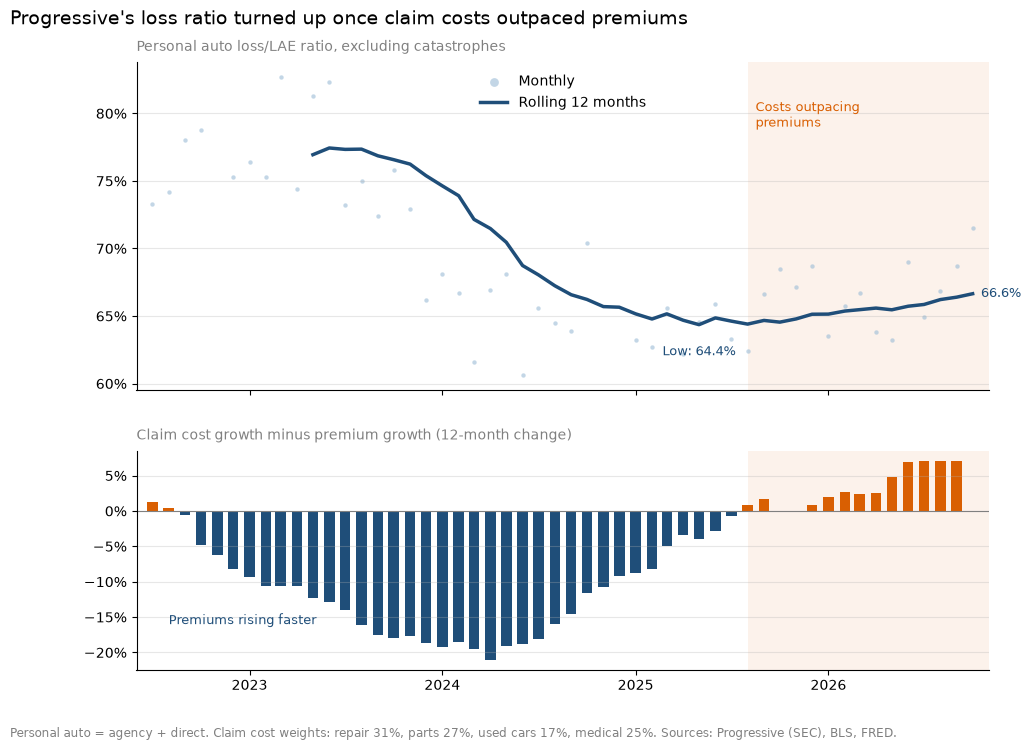

In [16]:
#plotting time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

plot = combined.loc["2022-07-01":]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"height_ratios": [3, 2], "hspace": 0.22})

#shade the period since claim costs started outpacing premiums (first positive gap from 2025 on)
recent = plot.loc["2025-01-01":]
turn = recent.index[recent["gap"] > 0].min()
for ax in (ax1, ax2):
    ax.axvspan(turn, plot.index.max() + pd.DateOffset(months=1), color="#d95f02", alpha=0.08, linewidth=0)

#Progressive's loss ratio excluding catastrophes
ax1.scatter(plot.index, plot["auto_ex_cat"], color="#9bbcd6", s=10, alpha=0.6, linewidth=0, label="Monthly")
ax1.plot(plot.index, plot["excat_12m"], color="#1f4e79", linewidth=2.5, label="Rolling 12 months")
ax1.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
fig.text(0.01, 0.99, "Progressive's loss ratio turned up once claim costs outpaced premiums", fontsize=14, va="top")
ax1.set_title("Personal auto loss/LAE ratio, excluding catastrophes", loc="left", fontsize=10, color="grey", pad=8)
ax1.text(turn + pd.DateOffset(days=15), 81, "Costs outpacing\npremiums", color="#d95f02", fontsize=9, va="top")
ax1.legend(frameon=False, loc="upper center", markerscale=2)

#label the low point and the latest value on the 12-month line
low = plot["excat_12m"].idxmin()
last = plot["excat_12m"].dropna().index.max()
ax1.annotate(f"Low: {plot.loc[low, 'excat_12m']:.1f}%", xy=(low, plot.loc[low, "excat_12m"]),
             xytext=(0, -22), textcoords="offset points", ha="center", fontsize=9, color="#1f4e79")
ax1.annotate(f"{plot.loc[last, 'excat_12m']:.1f}%", xy=(last, plot.loc[last, "excat_12m"]),
             xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="#1f4e79")

#claim cost growth minus premium growth
colors = ["#d95f02" if g > 0 else "#1f4e79" for g in plot["gap"].fillna(0)]
ax2.bar(plot.index, plot["gap"], width=20, color=colors)
ax2.axhline(0, color="grey", linewidth=0.8)
ax2.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax2.set_title("Claim cost growth minus premium growth (12-month change)", loc="left", fontsize=10, color="grey", pad=8)
ax2.text(pd.Timestamp("2022-08-01"), -0.16, "Premiums rising faster", color="#1f4e79", fontsize=9)

#years on the date axis
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax2.set_xlim(plot.index.min() - pd.DateOffset(months=1), plot.index.max() + pd.DateOffset(months=1))

for ax in (ax1, ax2):
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, 0.02, "Personal auto = agency + direct. Claim cost weights: repair 31%, parts 27%, used cars 17%, medical 25%. "
         "Sources: Progressive (SEC), BLS, FRED.", fontsize=8.5, color="grey")

fig.subplots_adjust(top=0.92)
fig.savefig("../images/progressive_vs_gap.png", dpi=200, bbox_inches="tight")
plt.show()

Progressive’s 12-month personal auto loss ratio, excluding catastrophes, fell from about 77% in 2023 to a low of 64.4% in mid-2025 while premiums grew faster than claim costs. After claim costs began outpacing premiums in late 2025, it rose to 66.6% by October 2026, and the monthly ratio reached 71.5%; this matches the cost-premium gap in the CPI data.